In [1]:
import dispatch
import dispatch.select as ds; import dispatch.graphics as dg;
import dispatch.yt as dyt
import matplotlib.pyplot as pl
import numpy as np

In [60]:
data='../data'
run = ''
start=0
end=21

In [7]:
def im3(pp,iv,vmin,vmax,varname): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    n[2]=1
    g=pp.patches[0].ng
    m=int(n[1]/2 -1)
    pos_arr = np.zeros([int(pp.cartesian.dims[0]),int(pp.cartesian.dims[1]),int(pp.cartesian.dims[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int((p.position[0]-pp.cartesian.origin[0])*pp.cartesian.dims[0]), int((p.position[1]-pp.cartesian.origin[1])*pp.cartesian.dims[1]), int(p.position[2])]
        #position=[0,0,0]
        #print (pp.cartesian.dims)
        #print (ip,position,p.position)
        pos_arr[position[0], position[1], position[2]] = p.id
        #if (iv==10):
        #    data= (p.var(5)**2+p.var(6)**2)/(8*np.pi)
        #    varname='magnetic pressure'
        #elif (iv==11):
        #    data= (p.var(4)*(s.gamma-1.0))
        #    varname='gas pressure'
        #else:
        data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],:]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
    #print(pos_arr)
    #print(np.shape(patch_arr.transpose()))
    #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    final = patch_arr[:,:,0].transpose()
    pl.imshow(final, cmap='viridis')
    pl.title(varname); 
    pl.colorbar(shrink=0.6)

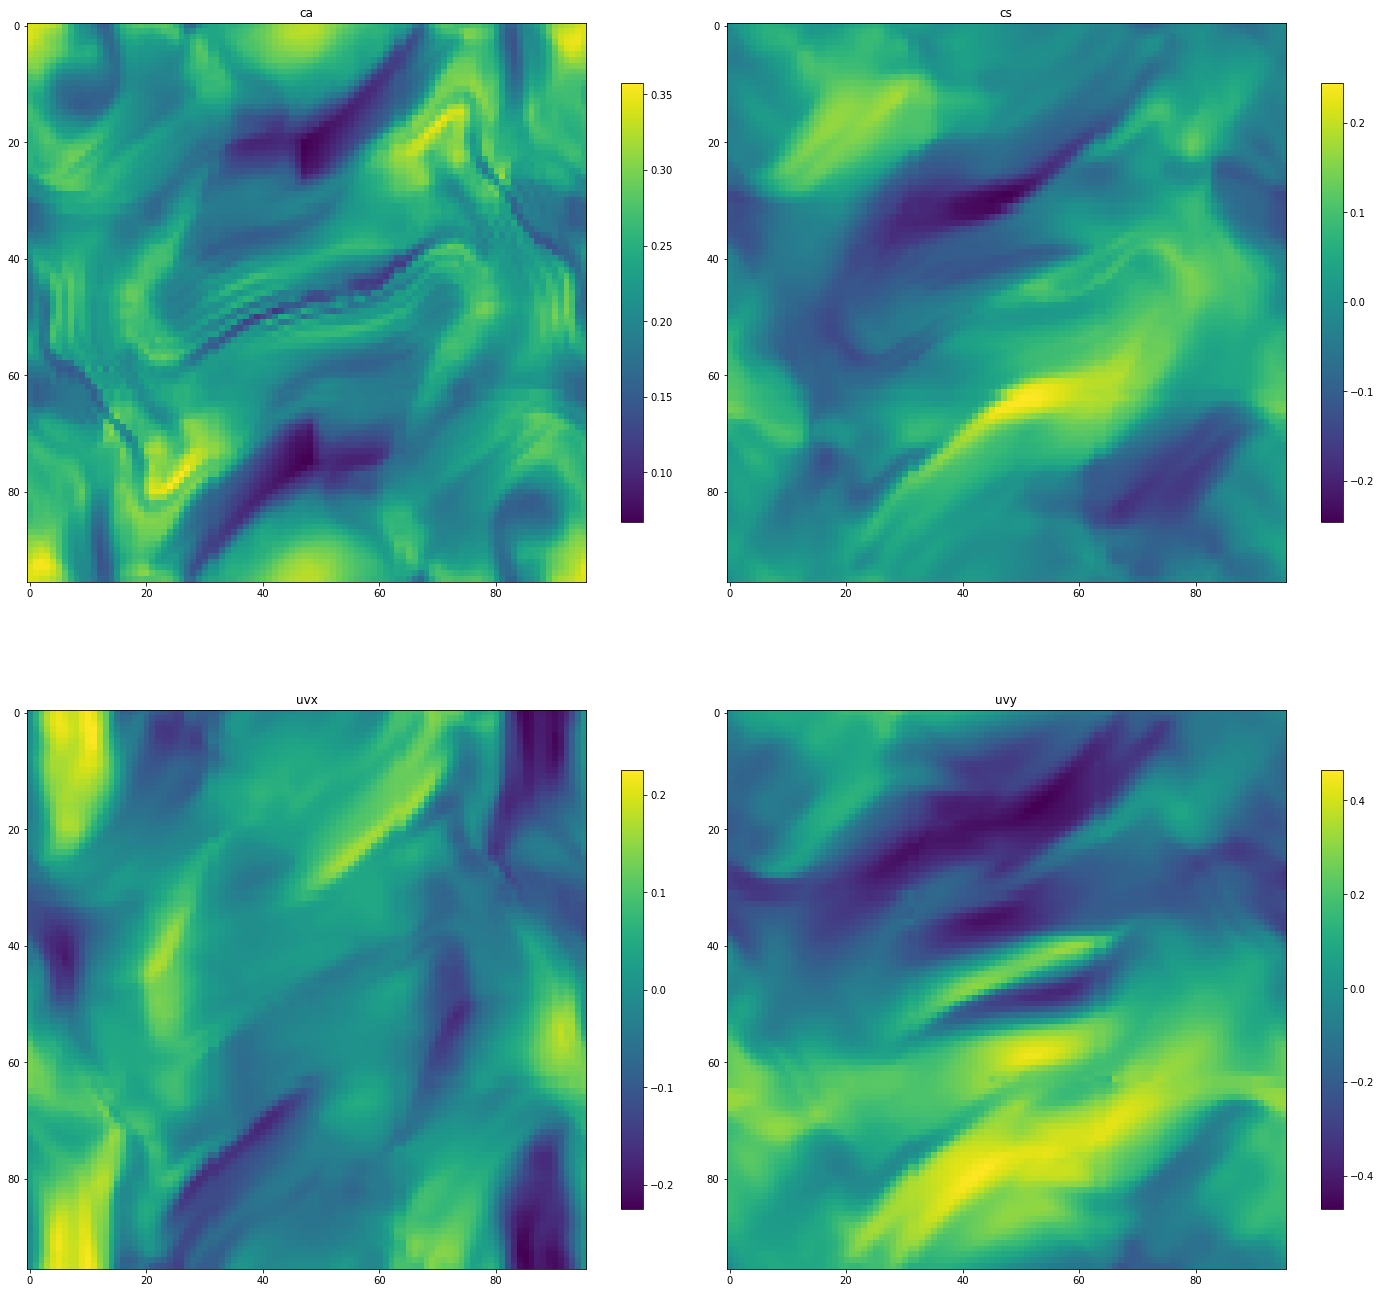

In [138]:
iout=100
s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
pl.figure(1, figsize=(20,20))
pl.clf()
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.subplot(2,2,1); im3(s, 0, 470, 530 ,'ca')#,ylim0,ylim1)
pl.subplot(2,2,2); im3(s, 1, -.20, +.20 ,'cs' )
        #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
pl.subplot(2,2,3); im3(s, 2, -.20, +.20, 'uvx')#,ylim0,ylim1)
pl.subplot(2,2,4); im3(s, 5, -.20, +.20, 'uvy')#,ylim0,ylim1)
pl.tight_layout()
pl.draw()
pl.pause(0.001)
pl.show()

In [ ]:
for iout in range(0,17):
    s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
    #dg.image_plane(snap=s,x=None,y=None,z=0.0,iv=7,verbose=False)
    pl.figure(1, figsize=(20,20))
    pl.clf()
            #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
            #for ip in range(num_patches):
            #    pp = ss[it].patches[ip]
            #    #density = pp.data[0]
    pl.subplot(2,2,1); im3(s, 0, 470, 530 ,'d')#,ylim0,ylim1)
    pl.subplot(2,2,2); im3(s, 4, -.20, +.20 ,'e' )
            #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
    pl.subplot(2,2,3); im3(s, 5, -.20, +.20, 'bx')#,ylim0,ylim1)
    pl.subplot(2,2,4); im3(s, 6, -.20, +.20, 'by')#,ylim0,ylim1)
    pl.tight_layout()
    pl.draw()
    pl.pause(0.001)
    pl.show()